In [4]:
# ============================================================================
# EJERCICIO 3: SIMULACIÓN MONTECARLO - PROYECTO DE CONSULTORÍA
# Análisis de Riesgo e Incertidumbre - Sesión 7
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
np.random.seed(42)  # Para reproducibilidad

print("✅ Librerías importadas correctamente")
print("📊 Listo para simulación Montecarlo")

✅ Librerías importadas correctamente
📊 Listo para simulación Montecarlo


In [5]:
# ============================================================================
# PARÁMETROS DEL PROYECTO
# ============================================================================

# Número de simulaciones
n_simulaciones = 10000

# Inversión inicial
inversion_inicial = 80000  # $80,000

# Horizonte de tiempo
meses = 12
wacc_anual = 0.15
wacc_mensual = (1 + wacc_anual)**(1/12) - 1

print("="*60)
print("PARÁMETROS DEL PROYECTO DE CONSULTORÍA")
print("="*60)
print(f"Inversión inicial: ${inversion_inicial:,.0f}")
print(f"Horizonte: {meses} meses")
print(f"WACC anual: {wacc_anual:.1%}")
print(f"WACC mensual: {wacc_mensual:.4%}")
print(f"Simulaciones: {n_simulaciones:,}")
print("="*60)

# ============================================================================
# GENERAR VARIABLES ALEATORIAS
# ============================================================================

# 1. PRECIO POR HORA: Normal(media=$150, desv=$20)
precio_por_hora = np.random.normal(loc=150, scale=20, size=n_simulaciones)
precio_por_hora = np.maximum(precio_por_hora, 80)  # Límite mínimo razonable

# 2. HORAS VENDIDAS/MES: Triangular(min=120, moda=160, max=200)
horas_vendidas_mes = np.random.triangular(
    left=120,
    mode=160,
    right=200,
    size=n_simulaciones
)

# 3. OPEX MENSUAL: Normal(media=$18,000, desv=$2,500)
opex_mensual = np.random.normal(loc=18000, scale=2500, size=n_simulaciones)
opex_mensual = np.maximum(opex_mensual, 10000)  # Límite mínimo razonable

print("\n✅ Variables aleatorias generadas:")
print(f"   - Precio por hora: {len(precio_por_hora):,} valores")
print(f"   - Horas vendidas/mes: {len(horas_vendidas_mes):,} valores")
print(f"   - OPEX mensual: {len(opex_mensual):,} valores")

PARÁMETROS DEL PROYECTO DE CONSULTORÍA
Inversión inicial: $80,000
Horizonte: 12 meses
WACC anual: 15.0%
WACC mensual: 1.1715%
Simulaciones: 10,000

✅ Variables aleatorias generadas:
   - Precio por hora: 10,000 valores
   - Horas vendidas/mes: 10,000 valores
   - OPEX mensual: 10,000 valores


In [6]:
# ============================================================================
# MODELO DE SIMULACIÓN: CALCULAR VPN
# ============================================================================

# Arrays para almacenar resultados
vpn_simulaciones = np.zeros(n_simulaciones)
ingresos_mensuales = np.zeros(n_simulaciones)
utilidad_mensual = np.zeros(n_simulaciones)

for i in range(n_simulaciones):
    # Ingresos mensuales
    ingresos = precio_por_hora[i] * horas_vendidas_mes[i]
    ingresos_mensuales[i] = ingresos

    # Utilidad mensual (Ingresos - OPEX)
    utilidad = ingresos - opex_mensual[i]
    utilidad_mensual[i] = utilidad

    # Flujos de caja mensuales (asumiendo constantes por simplicidad)
    flujos_mensuales = np.full(meses, utilidad)

    # Calcular VPN
    # VPN = -Inversión + Σ(FCF_t / (1+r)^t)
    vpn = -inversion_inicial
    for t in range(1, meses + 1):
        vpn += flujos_mensuales[t-1] / (1 + wacc_mensual)**t

    vpn_simulaciones[i] = vpn

print("="*60)
print("SIMULACIÓN COMPLETADA")
print("="*60)
print(f"✅ {n_simulaciones:,} escenarios simulados exitosamente")
print("\nPrimeros 5 resultados de VPN:")
for i in range(5):
    print(f"   Simulación {i+1}: ${vpn_simulaciones[i]:,.0f}")

SIMULACIÓN COMPLETADA
✅ 10,000 escenarios simulados exitosamente

Primeros 5 resultados de VPN:
   Simulación 1: $3,714
   Simulación 2: $-25,314
   Simulación 3: $-49,163
   Simulación 4: $43,108
   Simulación 5: $-8,477


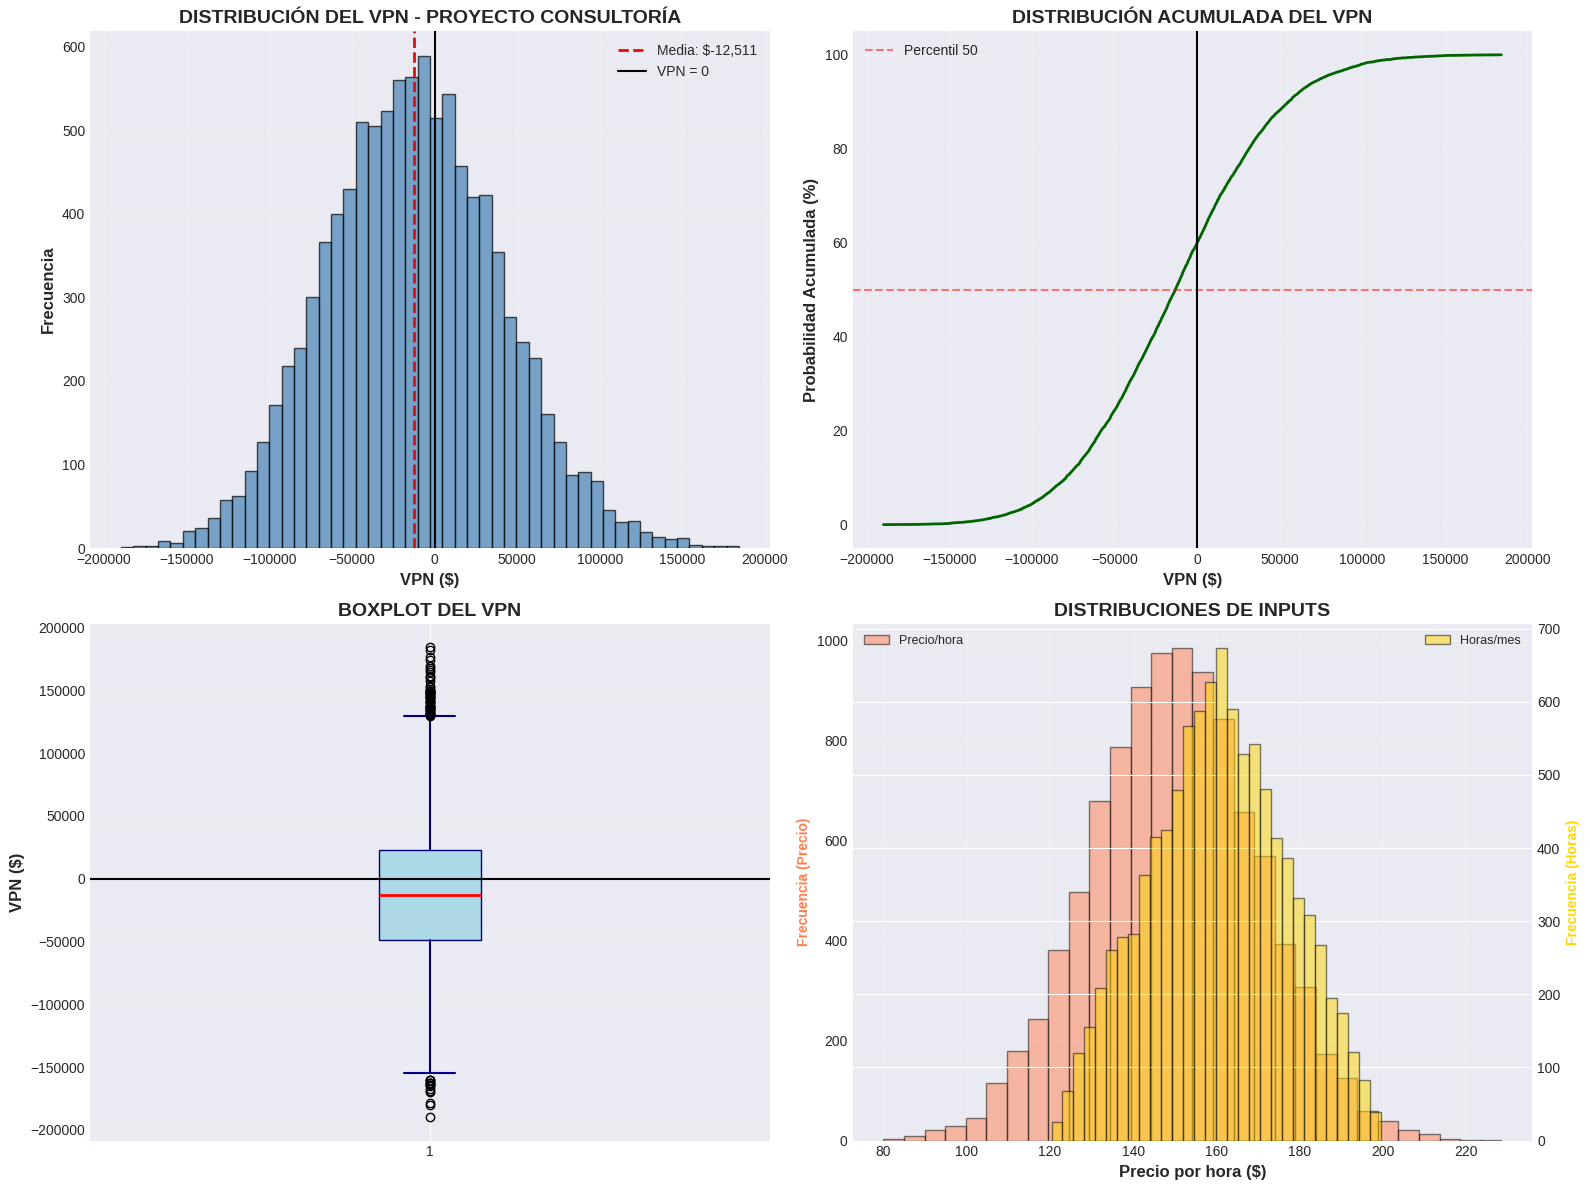

✅ Visualizaciones generadas correctamente


In [7]:
# ============================================================================
# VISUALIZACIÓN: HISTOGRAMA DE VPN
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Histograma del VPN
ax1 = axes[0, 0]
ax1.hist(vpn_simulaciones, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
ax1.axvline(vpn_simulaciones.mean(), color='red', linestyle='--', linewidth=2, label=f'Media: ${vpn_simulaciones.mean():,.0f}')
ax1.axvline(0, color='black', linestyle='-', linewidth=1.5, label='VPN = 0')
ax1.set_xlabel('VPN ($)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frecuencia', fontsize=12, fontweight='bold')
ax1.set_title('DISTRIBUCIÓN DEL VPN - PROYECTO CONSULTORÍA', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Gráfico 2: Distribución acumulada (CDF)
ax2 = axes[0, 1]
sorted_vpn = np.sort(vpn_simulaciones)
cumulative = np.arange(1, len(sorted_vpn) + 1) / len(sorted_vpn)
ax2.plot(sorted_vpn, cumulative * 100, color='darkgreen', linewidth=2)
ax2.axhline(50, color='red', linestyle='--', alpha=0.5, label='Percentil 50')
ax2.axvline(0, color='black', linestyle='-', linewidth=1.5)
ax2.set_xlabel('VPN ($)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Probabilidad Acumulada (%)', fontsize=12, fontweight='bold')
ax2.set_title('DISTRIBUCIÓN ACUMULADA DEL VPN', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

# Gráfico 3: Boxplot del VPN
ax3 = axes[1, 0]
box_data = ax3.boxplot(vpn_simulaciones, vert=True, patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='navy'),
                        medianprops=dict(color='red', linewidth=2),
                        whiskerprops=dict(color='navy', linewidth=1.5),
                        capprops=dict(color='navy', linewidth=1.5))
ax3.set_ylabel('VPN ($)', fontsize=12, fontweight='bold')
ax3.set_title('BOXPLOT DEL VPN', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')
ax3.axhline(0, color='black', linestyle='-', linewidth=1.5)

# Gráfico 4: Distribuciones de las variables de entrada
ax4 = axes[1, 1]
ax4.hist(precio_por_hora, bins=30, alpha=0.5, color='coral', label='Precio/hora', edgecolor='black')
ax4_twin1 = ax4.twinx()
ax4_twin1.hist(horas_vendidas_mes, bins=30, alpha=0.5, color='gold', label='Horas/mes', edgecolor='black')
ax4.set_xlabel('Precio por hora ($)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Frecuencia (Precio)', fontsize=10, fontweight='bold', color='coral')
ax4_twin1.set_ylabel('Frecuencia (Horas)', fontsize=10, fontweight='bold', color='gold')
ax4.set_title('DISTRIBUCIONES DE INPUTS', fontsize=14, fontweight='bold')
ax4.legend(loc='upper left', fontsize=9)
ax4_twin1.legend(loc='upper right', fontsize=9)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Visualizaciones generadas correctamente")

In [8]:
# ============================================================================
# ESTADÍSTICAS DESCRIPTIVAS Y MÉTRICAS DE RIESGO
# ============================================================================

# Cálculos estadísticos
media_vpn = vpn_simulaciones.mean()
mediana_vpn = np.median(vpn_simulaciones)
desv_vpn = vpn_simulaciones.std()
min_vpn = vpn_simulaciones.min()
max_vpn = vpn_simulaciones.max()
cv = desv_vpn / media_vpn if media_vpn != 0 else np.inf

# Percentiles
p05 = np.percentile(vpn_simulaciones, 5)
p10 = np.percentile(vpn_simulaciones, 10)
p25 = np.percentile(vpn_simulaciones, 25)
p75 = np.percentile(vpn_simulaciones, 75)
p90 = np.percentile(vpn_simulaciones, 90)
p95 = np.percentile(vpn_simulaciones, 95)

# Probabilidad de VPN positivo
prob_vpn_positivo = (vpn_simulaciones > 0).sum() / n_simulaciones * 100

# Value at Risk (VaR) al 95%
var_95 = np.percentile(vpn_simulaciones, 5)

# Conditional Value at Risk (CVaR) al 95%
cvar_95 = vpn_simulaciones[vpn_simulaciones <= var_95].mean()

# ============================================================================
# REPORTE DE RESULTADOS
# ============================================================================

print("\n" + "="*70)
print("📊 RESULTADOS DE LA SIMULACIÓN MONTECARLO")
print("="*70)
print(f"\n🎯 ESTADÍSTICAS CENTRALES:")
print(f"   E(VPN) - Valor Esperado:        ${media_vpn:>15,.0f}")
print(f"   Mediana VPN:                    ${mediana_vpn:>15,.0f}")
print(f"   Moda VPN (aprox.):              ${stats.mode(vpn_simulaciones.round(-3), keepdims=True)[0][0]:>15,.0f}")

print(f"\n📏 MEDIDAS DE DISPERSIÓN:")
print(f"   Desviación Estándar (σ):        ${desv_vpn:>15,.0f}")
print(f"   Coeficiente de Variación (CV):  {cv:>18.2f}")
print(f"   Rango (Max - Min):              ${max_vpn - min_vpn:>15,.0f}")

print(f"\n📊 RANGO DE RESULTADOS:")
print(f"   VPN Mínimo:                     ${min_vpn:>15,.0f}")
print(f"   VPN Máximo:                     ${max_vpn:>15,.0f}")

print(f"\n📈 PERCENTILES CLAVE:")
print(f"   Percentil  5% (P05):            ${p05:>15,.0f}")
print(f"   Percentil 10% (P10):            ${p10:>15,.0f}")
print(f"   Percentil 25% (P25):            ${p25:>15,.0f}")
print(f"   Percentil 50% (P50 - Mediana):  ${mediana_vpn:>15,.0f}")
print(f"   Percentil 75% (P75):            ${p75:>15,.0f}")
print(f"   Percentil 90% (P90):            ${p90:>15,.0f}")
print(f"   Percentil 95% (P95):            ${p95:>15,.0f}")

print(f"\n⚠️ MÉTRICAS DE RIESGO:")
print(f"   Probabilidad VPN > 0:           {prob_vpn_positivo:>17.2f}%")
print(f"   Value at Risk (VaR 95%):        ${var_95:>15,.0f}")
print(f"   CVaR 95% (Expected Shortfall):  ${cvar_95:>15,.0f}")

print(f"\n💡 INTERPRETACIÓN:")
if prob_vpn_positivo >= 80:
    decision = "✅ RECOMENDACIÓN: GO (Proyecto viable)"
    color = "verde"
elif prob_vpn_positivo >= 60:
    decision = "⚠️ RECOMENDACIÓN: CONDITIONAL (Requiere análisis adicional)"
    color = "amarillo"
else:
    decision = "❌ RECOMENDACIÓN: NO-GO (Proyecto muy riesgoso)"
    color = "rojo"

print(f"   {decision}")
print(f"   Nivel de confianza: {prob_vpn_positivo:.1f}%")
print(f"   Coeficiente de Variación: {cv:.2f} {'(Riesgo bajo)' if cv < 0.5 else '(Riesgo moderado)' if cv < 1 else '(Riesgo alto)'}")

print("\n" + "="*70)

# ============================================================================
# CREAR DATAFRAME DE RESUMEN
# ============================================================================

resultados_df = pd.DataFrame({
    'Métrica': ['E(VPN)', 'Mediana', 'Desv. Estándar', 'CV', 'VPN Min', 'VPN Max',
                'P05', 'P25', 'P75', 'P95', 'Prob(VPN>0)', 'VaR 95%', 'CVaR 95%'],
    'Valor': [f'${media_vpn:,.0f}', f'${mediana_vpn:,.0f}', f'${desv_vpn:,.0f}',
              f'{cv:.2f}', f'${min_vpn:,.0f}', f'${max_vpn:,.0f}',
              f'${p05:,.0f}', f'${p25:,.0f}', f'${p75:,.0f}', f'${p95:,.0f}',
              f'{prob_vpn_positivo:.2f}%', f'${var_95:,.0f}', f'${cvar_95:,.0f}']
})

print("\n📋 TABLA DE RESUMEN:")
print(resultados_df.to_string(index=False))


📊 RESULTADOS DE LA SIMULACIÓN MONTECARLO

🎯 ESTADÍSTICAS CENTRALES:
   E(VPN) - Valor Esperado:        $        -12,511
   Mediana VPN:                    $        -13,070
   Moda VPN (aprox.):              $        -18,000

📏 MEDIDAS DE DISPERSIÓN:
   Desviación Estándar (σ):        $         52,697
   Coeficiente de Variación (CV):               -4.21
   Rango (Max - Min):              $        374,012

📊 RANGO DE RESULTADOS:
   VPN Mínimo:                     $       -189,761
   VPN Máximo:                     $        184,251

📈 PERCENTILES CLAVE:
   Percentil  5% (P05):            $        -97,363
   Percentil 10% (P10):            $        -79,262
   Percentil 25% (P25):            $        -48,580
   Percentil 50% (P50 - Mediana):  $        -13,070
   Percentil 75% (P75):            $         22,659
   Percentil 90% (P90):            $         55,473
   Percentil 95% (P95):            $         75,313

⚠️ MÉTRICAS DE RIESGO:
   Probabilidad VPN > 0:                       40.13%